# **Banff Working Group Code**

Goal: Use Celia's existing code (to take a (finite) rectangle module and extract its critical values) and make matching distance more precise by computing lines instead of sampling lines along a grid. 

## Import all the things.


In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan,ceil, floor
import csv # this is for reading input files

import sys 
sys.path.append('../Code/')
import modules as mod

# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

# Functions

In [2]:
# importer function to run over rectangle rect mod (.rmod) data file

def import_rmod(filename):
    # here we import a file with a list of rectangles and the modules they belong to. 
    data = []
    datalist = {}
    templist = {}
    rectangles = {}
    # ERROR CHECKING
    try: fd = open(filename, 'r')
    except OSError:
        print("Could not open/read file")
        sys.exit()
    with fd:
        reader = csv.reader(fd, delimiter=':')
        num_entries = 0
        for row in reader:
            if not row:
                print("error! row not found!")
            num_entries = num_entries + 1
            data.append(list(row))
            datalist = []
            rectangles = []
        # LINE BY LINE READ IN 
        i = 0
        for x in data:
            temprectx1y1 = [float(item) for item in data[i][0].split()]
            temprectx2y2 = [float(item) for item in data[i][1].split()]
            temprectx3y3 = [float(item) for item in data[i][2].split()]
            temprectx4y4 = [float(item) for item in data[i][3].split()]
            tempdim = [int(item) for item in data[i][4].split()]
            tempid = [int(item) for item in data[i][5].split()]
            templist = [temprectx1y1, temprectx2y2,temprectx3y3,temprectx4y4, tempdim, tempid]
            temprectangle = mod.Rectangle(temprectx1y1,temprectx2y2,temprectx3y3,temprectx4y4, tempdim, tempid)
            datalist.append(templist)
            rectangles.append(temprectangle)
            i += 1
            
        # all_rectangles is a list with x1y1, x2y2, dim, parent module
        # TODO: we shuffle the same data between variabes; this could be cleaned
        all_rectangles = datalist
        # for every line in all_rectangles, make a mod.Rectangle, 
        # and then rmod.addrect() to the module in the ith position in 
        # a module list, corresponding to the parent id.
        rects_list = []
        r_mods_list = [None] * len(all_rectangles)
        # this is the max possible size it could be, but prob smaller
        # TODO: double check that this does the right thing
        i = 0
        for x in all_rectangles:
            temp_rect = mod.Rectangle((x[0][0], x[0][1]), (x[1][0], x[1][1]),(x[2][0], x[2][1]),(x[3][0], x[3][1]), x[4][0], x[5][0])
            rects_list.append(temp_rect)
            i += 1
        j = 0
        for y in rects_list:
            if r_mods_list[y.find_parent()] == None:
                # we need to initialize
                r_mods_list[y.find_parent()] = mod.RectangleModule([y])
            else:
                # this mod already initialized. append. 
                r_mods_list[y.find_parent()].add_rectangle(y)
                # should be [y]?!
            j += 1
        # this is a sneaky way using list comprehension to remove Nones
        r_mods_list = [i for i in r_mods_list if i]
    return r_mods_list

In [3]:
# r_mods_list = import_rmod('../data/sample.rmod')
r_mods_list = import_rmod('../data/sample_inf.rmod')
i = 0
for z in r_mods_list:
    print("Rectangle module", i , "info: ")
    print(z.rectangles)
    i += 1
# stopping point: right now, r_mods_list
# is a list of all of the modules from the rmod file. 
# next: incorporate this into function, and add printing
# to the rmods class in the modules file for error checking
# we can have duplicates of rectangles, but give a warning if so.
# types: right inf, top inf, completely inf, completely finite
# add error checking for types of inf, in case x and y mismatched or so




Rectangle module 0 info: 
[(dim is 1. Parent mod is 0. 
 Coords: 
 (0.0, 7.0) __________ (inf, 7.0) 
           |          | 
           |__________| 
 (0.0, 1.0)            (inf, 1.0) 
 )]
Rectangle module 1 info: 
[(dim is 1. Parent mod is 1. 
 Coords: 
 (0.0, 7.0) __________ (7.0, 7.0) 
           |          | 
           |__________| 
 (0.0, 1.0)            (7.0, 1.0) 
 )]


## Add lines and compute crit pts. 

In [4]:
L = mod.Line((1,1),(0,0))
L_low = mod.Line((1,1),(1/2,-1/2))
L_up = mod.line_through_2points((0,3),(7,10))
L_up.b

for i in range(0,len(r_mods_list)):
    M = r_mods_list[i]
#     M.print_mod_info()
    [inter_m1, param_m1] = M.find_intersection(L_low)
    print("inter of Module ", i, " : ", inter_m1,"\n")
    dgmM = M.compute_barcode(L_low)
    print("DGM of Module ", i, " : ",dgmM,"\n")
    print("crit + LUB of Module ", i, " : ", M.find_critical_pts() + M.closure_lub(),"\n")

inter of Module  0  :  [[(2.0, 1.0), (8.0, 7.0)]] 

DGM of Module  0  :  [[1.5, 7.5]] 

crit + LUB of Module  0  :  [(0.0, 1.0), (0.0, 7.0), (0.0, 1.0), (0.0, 7.0)] 

inter of Module  1  :  [[(2.0, 1.0), (7.0, 6.0)]] 

DGM of Module  1  :  [[1.5, 6.5]] 

crit + LUB of Module  1  :  [(0.0, 1.0), (0.0, 7.0), (7.0, 1.0), (7.0, 7.0), (0.0, 1.0), (0.0, 7.0), (7.0, 1.0), (7.0, 7.0)] 



## Plot modules + pwise bottleneck

we have  2  rectangles


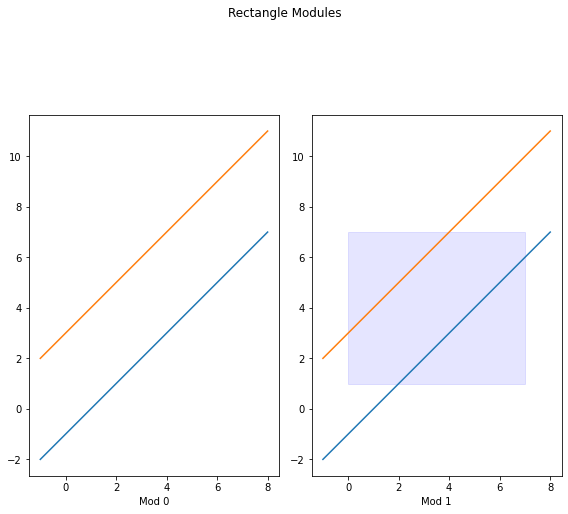

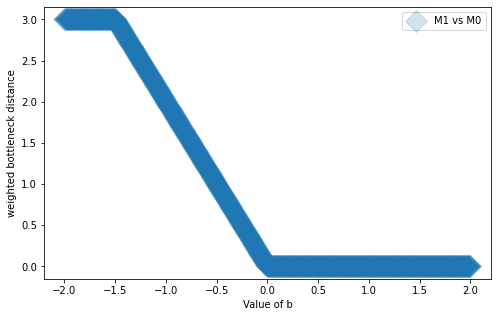

In [21]:
#TODO: incorporate inf

n_mods = len(r_mods_list)
n_rects = 0
for i in range(len(r_mods_list)):
    n_rects += r_mods_list[i].count_rectangles()
print("we have ", n_rects, " rectangles")

color_n = (0.1, 0.2, 0.3)
fig, axes = plt.subplots(1, n_mods, figsize=(8, 8))
# this only prints the correct number of plots, but later we would
# also like them to be organized nicely and not in a column

for i in range(n_mods):
    for j in range(r_mods_list[i].count_rectangles()):
        # this for loop runs over all rectangles in all mods. 
        # we need to hold it at this size to hit all rectangles, 
        # even though we don't want to have this many plots.        
        temp_rect = r_mods_list[i].rectangles[j]
        # this is the current rectangle
        a1 = temp_rect.bottom_left 
        h1= temp_rect.top_right[0]- a1[0]
        v1= temp_rect.top_right[1]- a1[1]
        temp_patch = matplotlib.patches.Rectangle(a1,h1,v1,color = 'blue', alpha = 0.1)       
        color_n = (color_n[0] + 0.01,color_n[1]+ 0.1,color_n[2]+ 0.01)
        #TODO: make sure always in 0-1 range or represent differently
        # here, we need to print the right things
        ax = axes[r_mods_list[i].rectangles[j].find_parent()]
        ax.add_patch(temp_patch)
        x = np.linspace(-1, 8, 1000)
        # lines to plot
#         ax.plot(x, x + 0, linestyle='solid') 
        ax.plot(x, x -1, linestyle='solid') 
        ax.plot(x, x + 3, linestyle='solid') 
        ax.set_aspect(1)
        ax.set_xlabel('Mod ' + str(i))
#         fig = ax.get_figure() 
        fig.tight_layout()
        fig.suptitle('Rectangle Modules')
#         fig.subplots_adjust(top=0.9)

ii = 0
jj = 0
a = 0
fig, ax = plt.subplots(figsize=(8, 5))
for M in r_mods_list: 
    for N in r_mods_list:
        if ii < jj:
            # this gets rid of half of the matrix of entries, 
            # keeping only the lower half. That way if we have
            # wlog (1,3), we don't also get (3,1). 
            # equality leaves (x,x) for sanity checks; 
            # can be eliminated by removing equality. 
            
            ## Family of lines in same equivalence class 
            n = 100 ## number of points in interval 
            t = 5/n 
            q = 2
            # q = 1.5
            # t is length of interval
            Lines = []
            wbd=[]
            x=[]
#             for i in range(n+1):
#                 b= i*t
#                 x.append(-q +b)
#                 #print(b)
#                 line = mod.Line((1,1),(-q +b,q -b))
#                 #TODO: instead of hardcoded lines, 
#                 # use critical values to find reasonable parameters
#                 Lines.append(line)
#                 d = mod.compute_weighted_bottleneck(M,N,line)
#                 wbd.append(d)
            for b in np.linspace(-2, 2, 1000):
                x.append(b)
                line = mod.Line((1,1), (b , -b))
                Lines.append(line)
                d = mod.compute_weighted_bottleneck(M,N,line)
                wbd.append(d)
            ax.set_aspect('auto')
            ax.plot(x, wbd, 'D', markersize = 15, alpha = 0.2, label='M' + str(jj) + ' vs M'+ str(ii))
            #ax.title('(weighted) bottleneck distance between M ' + str(jj) + ' and M '+ str(ii))
            ax.set_xlabel('Value of b')
            ax.set_ylabel('weighted bottleneck distance')
            ax.legend()
            a += 1
            #fig.suptitle('(w) bdist between M ' + str(jj) + ' and M '+ str(ii))
        jj += 1
    ii += 1
    jj = 0
    

plt.show()

# issues: 
# inf (causes many problems, among them discontinuity)
# same verts in rectangle (so not a proper rectangle) (causes discont)
# other problems with rectangle: like being at an angle instead of x,y aligned
# add error checking to disallow bad rectangle input
# add error checking to make sure that all rectangles per mod have same dim
# allow option for separate plots since sometimes things get stacked
# for inf rectangles: do multiple coords need to be inf? or just one? 
# interval modules can be non-axis aligned, but not rect mods
# if we only have one module, we get the error of ax not being subscriptable
# add smart finding of lines

# infs: 
# if a coord is (inf inf), there is no rectangle displayed


# TO DO 

### ERROR CHECKING, importer func + mod class: 
- mod.rectmod : check that all dimensions are the same in a mod
- remove duplicate rectangles if any, or at least warn
- check that numbers make sense, like dim is + 
- also check sensible numbers in mod.rect 
- Question: could two parent modules share same rectangle?

## NOTES (eventually for a README)

An example of a line of input to an .rmod file: 

```0.0 7.0 : inf inf : 0 1 : 7 1 : 1 : 0 ```

This defines a rectangle: four verts, dimension, parent module.
inf is converted automatically by python to np.inf: the following returns True. 

```if x[1][0] == float('inf'):
       print(x[1][0] == np.inf)``` 
       
Further, all inputs are converted to float, so it is fine to enter either ints or floats. 

Warning: the file should not end with empty lines. This can be checked in a text editor such as Sublime. 